# Fig 2. Method schematic

Data -> two parallel pipelines (explanatory, lagged-only) -> the same four evaluation steps.
Drawn at the real journal width (7.5 in) so that the type sizes below are the printed sizes.
Everything editable is in the Settings cell: sizes, colours, texts, the marker shapes of the icons.
Redesigned 2026-09-21 (the first version was a plain row of boxes at 12.6 in, whose type would have printed at ~4.5 pt).

In [1]:
# Setup
import sys
from pathlib import Path
HERE = Path.cwd().resolve()
sys.path.insert(0, str(HERE.parent)); sys.path.insert(0, str(HERE.parents[1]))
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle
from style import *

In [2]:
# Settings (edit here, then Run All)
S = dict(
    # 2026-09-23: scaled up 1.3x from the original (7.5, 5.0)/(7.6, 6.5, 6.0, 8.0) -- small text at the
    # original size rendered illegibly (readable as "neura", "leave not eace", "foel prediction baseline
    # repication" instead of "neural", "leave one year", "model prediction, baseline, replication"). Scaling
    # the canvas and every font size together keeps the same layout proportions at a legible size.
    # 2026-09-24: canvas and fonts scaled up again -- still reading small next to every other figure's
    # bumped fonts. Canvas grows a bit less than the fonts (not the full proportional amount) so the
    # boxes' internal text gets more breathing room, not just bigger letters in the same space.
    figsize=(10.6, 7.1),                       # inches; 1 drawing unit = 0.065 in
    title_fs=11.5, body_fs=10, small_fs=9, lane_fs=12,
    lane_colours=(NAVY, "#7A6C9E"),           # explanatory, lagged-only
    lane_tint_alpha=0.07,
    box_lw=1.0, arrow_lw=1.1,
    heldout_colour=RED,                       # the held-out year in the leave-one-year-out icon
    n_years=9, year_marker_size=2.4,          # leave-one-year-out icon
    heldout_index=4,
    pareto_marker="o", pareto_ms=2.2, chosen_marker="*", chosen_ms=6,
    termmap_rows=4, termmap_cols=8,
)
TEXT = dict(
    data_title="Daily data, Bogotá and Medellín",
    data_items=[("Targets", "PM$_{2.5}$ and O$_3$ (MDA8)\nfrom monitoring networks"), ("Station meteorology", "temperature, humidity,\nwind, pressure"),
                ("ERA5 reanalysis", "boundary layer, radiation,\nw$_{700}$, moisture"), ("Chemistry", "CO, NO, NO$_2$\n(satellite check: TROPOMI)"), ("Fire hotspots", "satellite counts by\ndirection sector")],
    lanes=[("Explanatory pipeline", "same-day predictors: what controls the pollutant", "Figures 3–5"),
           ("Lagged-only pipeline", "predictors at least one day old: what predicts the next day", "Figures 5c and S9")],
    steps=[("Candidate pool", ["same-day and lagged\nmeteorology, chemistry\nand fire hotspots", "every predictor at least\none day old; no lag of the\ntarget, no calendar terms"]),
           ("Feature selection", ["forward selection with a\nneural net, scored on\nheld-out years"] * 2),
           ("Symbolic regression", ["PySR: free-form and\ndimensionally constrained\nsearches"] * 2),
           ("Best equation first", ["read the Pareto front from\nthe top; keep the terms that\npersist as complexity falls"] * 2)],
    eval_title="Evaluation, identical for both pipelines and both cities",
    evals=["R² of pooled out-of-fold\npredictions, leave one year\nout (constants refitted)", "persistence baseline:\nlinear fit on yesterday's\nvalue, same days", "falsification by inclusion:\nadd a rival variable, does\nit displace the term?", "replication: do the same\nterms reappear without\nsame-day values, and in\nanother city?"],   # R9: "linear fit on yesterday's value", not "yesterday's value only"
)

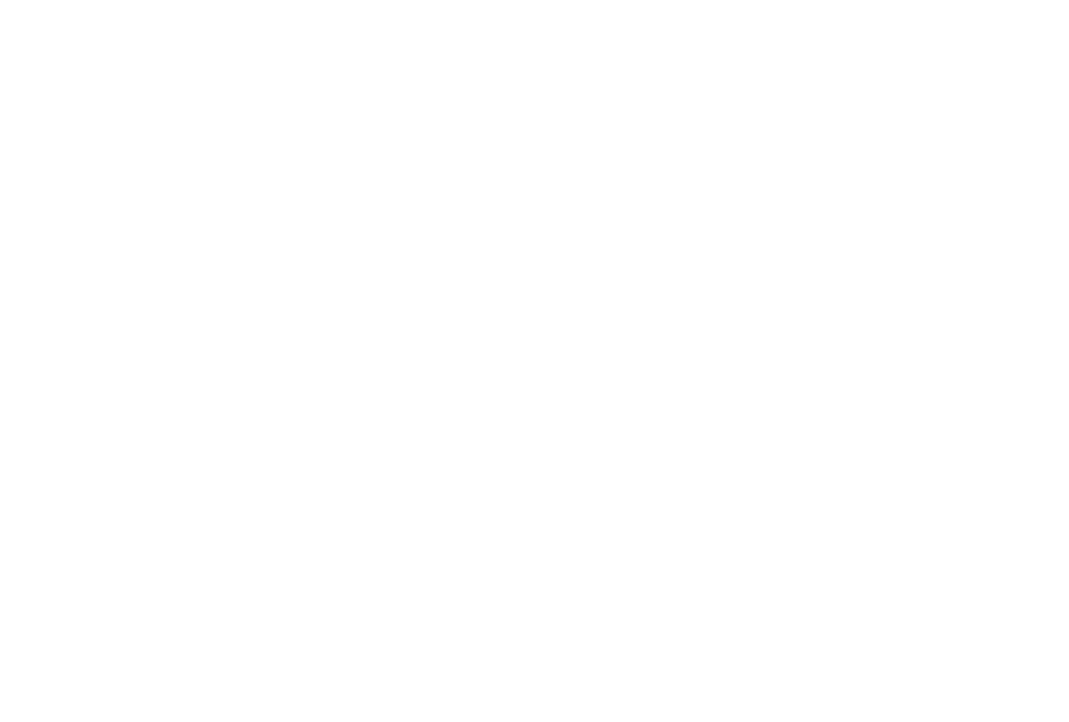

In [3]:
# Drawing helpers
W, H = 150, 100
fig, ax = plt.subplots(figsize=S["figsize"]); ax.set_xlim(0, W); ax.set_ylim(0, H); ax.axis("off"); fig.subplots_adjust(0.005, 0.005, 0.995, 0.995)

def rbox(x, y, w, h, ec=NAVY, fc="white", lw=None, r=1.2, alpha=1, z=2):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle=f"round,pad=0,rounding_size={r}", fc=fc, ec=ec, lw=S["box_lw"] if lw is None else lw, alpha=alpha, zorder=z))

def arrow(p0, p1, col=NAVY):
    ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle="-|>", mutation_scale=8, color=col, lw=S["arrow_lw"], shrinkA=0, shrinkB=0, zorder=4))

def txt(x, y, s, fs, **kw):
    kw.setdefault("color", NAVY); kw.setdefault("ha", "left"); kw.setdefault("va", "top"); kw.setdefault("linespacing", 1.25)
    return ax.text(x, y, s, fontsize=fs, zorder=5, **kw)

# --- icons (all drawn inside a box whose lower-left corner is (x, y) and width w)
def icon_pool(x, y, w, col, lagged):
    rng = np.random.default_rng(3); yy = y + 11.0
    for r in range(3):
        xx = x + 2.0
        while xx < x + w - 6:
            cw = rng.choice([3.0, 4.2, 5.4]); ax.add_patch(Rectangle((xx, yy - 3.0), cw, 2.4, fc=col, ec="white", lw=0.4, alpha=0.75 - 0.15 * r, zorder=4)); xx += cw + 0.8
        yy -= 3.4
    if lagged: txt(x + w - 2, y + 11.8, "t−1", S["small_fs"], color=col, ha="right", va="top", fontweight="bold")

def icon_loyo(x, y, w, col):
    n, m = S["n_years"], S["year_marker_size"]; gap = 0.55; tot = n * m + (n - 1) * gap; x0 = x + (w - tot) / 2
    for i in range(n):
        held = i == S["heldout_index"]
        ax.add_patch(Rectangle((x0 + i * (m + gap), y + 6.2), m, m, fc=S["heldout_colour"] if held else col, ec="none", alpha=1 if held else 0.55, zorder=4))
    txt(x + w / 2, y + 4.6, "train on the others,\nscore the held-out year", S["small_fs"], ha="center", style="italic")

def icon_equation(x, y, w, col):
    txt(x + w / 2, y + 12.8, r"$\hat{y}=\frac{c_1\sqrt{x_1}}{x_2+c_2}$", 15, ha="center")

def icon_termmap(x, y, w, col):
    R, C = S["termmap_rows"], S["termmap_cols"]; cw = min(3.2, (w - 6) / C); ch = 2.1; x0 = x + (w - C * cw) / 2; y0 = y + 12.6
    for r in range(R):
        for c in range(C):
            if c >= r * 1.5:                                   # a variable enters at some complexity and stays
                ax.add_patch(Rectangle((x0 + c * cw, y0 - (r + 1) * ch), cw * 0.92, ch * 0.88, fc=col, ec="none", alpha=0.85, zorder=4))
    ax.add_patch(Rectangle((x0 + (C - 1) * cw - 0.3, y0 - R * ch - 0.3), cw * 0.92 + 0.6, R * ch + 0.5, fc="none", ec=RED, lw=0.9, zorder=5))
    txt(x + w / 2, y + 3.2, "variable × complexity", S["small_fs"], ha="center", style="italic")

In [4]:
# Figure
# data bar
rbox(0.8, 88, W - 1.6, 11.6, ec=GREY, fc=LIGHT, lw=0.8)
txt(2.5, 98.9, TEXT["data_title"], S["title_fs"], fontweight="bold")
n_it = len(TEXT["data_items"]); step = (W - 5) / n_it
for i, (t, b) in enumerate(TEXT["data_items"]):
    x0 = 2.5 + i * step
    txt(x0, 95.6, t, S["small_fs"] + 0.3, fontweight="bold"); txt(x0, 93.4, b, S["small_fs"])

# lanes
box_x = [5, 41, 77, 113]; bw, bh = 32, 27
lane_y = [(52, 50, 87), (15.4, 13.4, 49)]                     # (box bottom, band bottom, band top)
for (lab, sub, ref), (by, band0, band1), col, li in zip(TEXT["lanes"], lane_y, S["lane_colours"], (0, 1)):
    ax.add_patch(Rectangle((0.8, band0), W - 1.6, band1 - band0, fc=col, alpha=S["lane_tint_alpha"], ec="none", zorder=1))
    txt(2.5, band1 - 1.0, lab, S["lane_fs"], color=col, fontweight="bold")
    txt(2.5 + 0.0 + len(lab) * 1.62, band1 - 1.6, sub, S["small_fs"], color=col, style="italic")
    txt(W - 2.5, band1 - 1.6, ref, S["small_fs"], color=col, ha="right")
    for k, ((title, bodies), bx) in enumerate(zip(TEXT["steps"], box_x)):
        rbox(bx, by, bw, bh, ec=col)
        txt(bx + 1.8, by + bh - 1.6, f"{k + 1}  {title}", S["title_fs"], color=col, fontweight="bold")
        txt(bx + 1.8, by + bh - 6.0, bodies[li], S["body_fs"])
        if k == 0: icon_pool(bx, by, bw, col, li == 1)
        else: [None, icon_loyo, icon_equation, icon_termmap][k](bx, by, bw, col)
        if k < 3: arrow((bx + bw + 0.3, by + bh / 2), (box_x[k + 1] - 0.3, by + bh / 2), col)
    arrow((2.2, by + bh / 2), (box_x[0] - 0.3, by + bh / 2), col)
ax.plot([2.2, 2.2], [88, lane_y[1][0] + bh / 2], color=NAVY, lw=S["arrow_lw"], zorder=3)

# evaluation strip
rbox(0.8, 0.8, W - 1.6, 11.8, ec=GREY, fc=LIGHT, lw=0.8)
txt(2.5, 12.0, TEXT["eval_title"], S["title_fs"], fontweight="bold")
step = (W - 5) / len(TEXT["evals"])
for i, t in enumerate(TEXT["evals"]):
    txt(2.5 + i * step, 8.5, "•  " + t.replace("\n", "\n    "), S["small_fs"] + 0.2)
save_fig(fig, "fig02_method_schematic", line_art=True)

saved /path/to/project/Paper/figures/fig02_method_schematic.png
